# Tarea P4b: reconocimiento de caracteres en matrículas

Continuación de la P4 (`../P4`). Pasos:

1. **Conjunto de evaluación**: matrículas del split de *test* del dataset de la P4, con su texto real (campo `plate` de las anotaciones originales).
2. **Comparativa de dos OCR** en las mismas condiciones: un OCR clásico, **EasyOCR**, y un VLM, **SmolVLM-256M-Instruct**.
   Se mide la tasa de acierto (matrícula completa y por carácter) y el tiempo de inferencia.
3. **Integración en el prototipo**: se lee el texto de cada matrícula detectada en el vídeo de test, se rellena `texto_matricula` en el CSV
   y se genera un vídeo que muestra la matrícula leída.

In [1]:
import os, re, json, glob, time, platform, subprocess, random
from collections import defaultdict, Counter
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from PIL import Image

P4       = os.path.abspath('../P4')
RAW_ANN  = os.path.join(P4, 'dataset_raw', 'annotations')   # .json originales con el texto de cada matrícula
DATA_DIR = os.path.join(P4, 'dataset_matriculas')           # imágenes ya reescaladas (P4)
OUT_DIR  = 'resultados'
IMG_DIR  = 'imagenes'
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(IMG_DIR, exist_ok=True)
torch.set_num_threads(os.cpu_count())

# Especificaciones de la máquina (los tiempos dependen mucho del equipo)
cpu = next((l.split(':', 1)[1].strip() for l in open('/proc/cpuinfo') if l.startswith('model name')), platform.processor())
ram = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 2**30
print(f'CPU: {cpu} ({os.cpu_count()} hilos), RAM: {ram:.0f} GB, GPU: no (CUDA={torch.cuda.is_available()})')
print(f'{platform.system()} {platform.release()}, Python {platform.python_version()}, torch {torch.__version__}')

CPU: AMD Ryzen AI 7 445 w/ Radeon 840M (12 hilos), RAM: 30 GB, GPU: no (CUDA=False)
Linux 7.2.11-200.fc44.x86_64, Python 3.11.17, torch 2.15.0+cpu


## 1. Conjunto de evaluación

Cada `.json` de `dataset_raw/annotations` contiene, para cada matrícula de la imagen, su caja normalizada `rectangle = [xc, yc, w, h]` y el texto `plate`.
Para que la comparativa sea honesta se usan solo las imágenes del **split de test** de la P4.

- Se descartan las matrículas anotadas como `None`/`NONE`: el anotador las marcó como ilegibles, así que no hay texto con el que comparar.
- Cada matrícula se recorta de la imagen con un pequeño margen (5 % en horizontal, 15 % en vertical). **Los dos OCR reciben exactamente el mismo recorte.**

In [2]:
MARGEN_X, MARGEN_Y = 0.05, 0.15
FORMATO_ACTUAL  = re.compile(r'\d{4}[A-Z]{3}')        # 1234ABC (desde 2000)
FORMATO_ANTIGUO = re.compile(r'[A-Z]{1,2}\d{4}[A-Z]{1,2}')  # GC1234AB (provincial)

def recorta(img, xc, yc, w, h):
    H, W = img.shape[:2]
    x1, y1 = int(max(0, (xc - w/2 - MARGEN_X*w) * W)), int(max(0, (yc - h/2 - MARGEN_Y*h) * H))
    x2, y2 = int(min(W, (xc + w/2 + MARGEN_X*w) * W)), int(min(H, (yc + h/2 + MARGEN_Y*h) * H))
    return img[y1:y2, x1:x2]

muestras = []
for ip in sorted(glob.glob(os.path.join(DATA_DIR, 'test', 'images', '*.jpg'))):
    base = os.path.splitext(os.path.basename(ip))[0]
    jp = os.path.join(RAW_ANN, base + '.json')
    if not os.path.exists(jp):
        continue
    img = cv2.imread(ip)
    for k, o in enumerate(json.load(open(jp, encoding='utf-8'))):
        texto = (o.get('plate') or '').strip().upper()
        xc, yc, w, h = map(float, o['rectangle'])
        if texto in ('', 'NONE') or w <= 0 or h <= 0:
            continue
        c = recorta(img, xc, yc, w, h)
        if c.shape[0] < 4 or c.shape[1] < 8:
            continue
        formato = 'actual' if FORMATO_ACTUAL.fullmatch(texto) else ('antiguo' if FORMATO_ANTIGUO.fullmatch(texto) else 'otro')
        muestras.append({'id': f'{base}#{k}', 'texto_real': texto, 'formato': formato,
                         'ancho_px': c.shape[1], 'alto_px': c.shape[0], 'recorte': c})

ev = pd.DataFrame(muestras)
print(f'Matrículas legibles en test: {len(ev)} (de {ev["id"].str.split("#").str[0].nunique()} imágenes)')
display(ev['formato'].value_counts().to_frame('matrículas'))
display(ev[['ancho_px', 'alto_px']].describe().round(1).T)

Matrículas legibles en test: 629 (de 439 imágenes)


,matrículas
formato,
actual,594
antiguo,32
otro,3


,count,mean,std,min,25%,50%,75%,max
ancho_px,629.0,99.1,78.9,12.0,43.0,71.0,132.0,529.0
alto_px,629.0,51.3,60.9,4.0,17.0,30.0,60.0,491.0


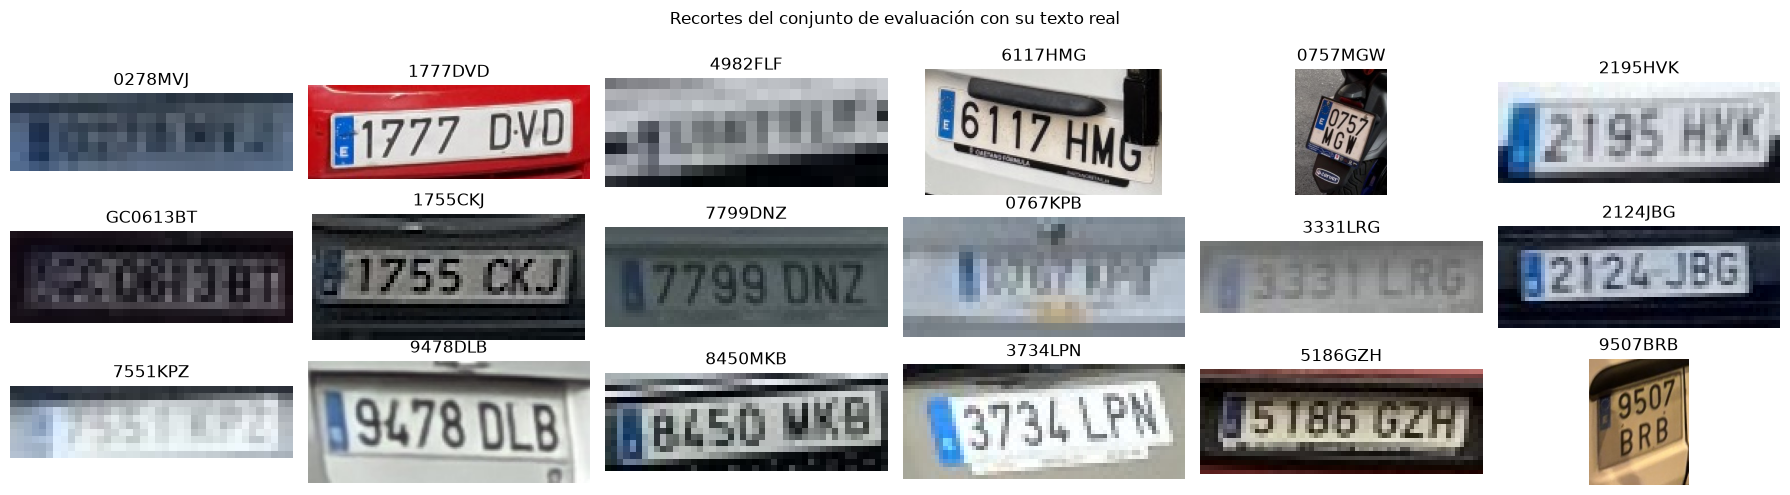

In [3]:
random.seed(0)
fig, axs = plt.subplots(3, 6, figsize=(18, 5))
for ax, i in zip(axs.ravel(), random.sample(range(len(ev)), 18)):
    ax.imshow(ev.recorte[i][:, :, ::-1]); ax.set_title(ev.texto_real[i]); ax.axis('off')
plt.suptitle('Recortes del conjunto de evaluación con su texto real'); plt.tight_layout(); plt.show()

## 2. Modelos

**Preprocesado común**: si el recorte mide menos de 64 px de alto, se amplía (interpolación cúbica) hasta 64 px. Así los dos modelos ven la misma imagen.

**Normalización común de la salida**: se pasa a mayúsculas y se dejan solo letras y dígitos. Si en el resultado aparece un patrón de matrícula española
(`1234ABC` o `GC1234AB`), se queda solo ese patrón. Así no penaliza leer la banda azul (`E`) o algún carácter suelto del borde.

- **EasyOCR** (detector CRAFT + reconocedor CRNN). Se restringe el alfabeto a `0-9A-Z` con `allowlist`, y los fragmentos detectados se concatenan de izquierda a derecha.
- **SmolVLM-256M-Instruct** (HuggingFace, 256 M parámetros). Prompt: *"Read the text on this license plate. Answer only with the characters."*,
  decodificación voraz y como máximo 16 tokens.
  Se **desactiva el `image splitting`**: por defecto parte cada imagen en 9 *tiles* de 512 px (619 tokens), lo que en CPU llevaba unos 10 s por recorte.
  Sin él baja a menos de 3 s y en las pruebas lee igual, porque un recorte de matrícula es pequeño.

In [4]:
ALTO_MIN = 64
def preprocesa(c):
    if c.shape[0] < ALTO_MIN:
        s = ALTO_MIN / c.shape[0]
        c = cv2.resize(c, (int(round(c.shape[1] * s)), ALTO_MIN), interpolation=cv2.INTER_CUBIC)
    return c

def normaliza(t):
    t = re.sub(r'[^A-Z0-9]', '', (t or '').upper())
    m = FORMATO_ACTUAL.search(t) or FORMATO_ANTIGUO.search(t)
    return m.group(0) if m else t

def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j-1] + 1, prev + (ca != cb))
    return d[-1]

# --- EasyOCR ---
import easyocr
lector = easyocr.Reader(['en'], gpu=False, verbose=False)
ALFABETO = '0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ'

def ocr_easyocr(c):
    # Devuelve (texto, confianza media)
    r = sorted(lector.readtext(c, allowlist=ALFABETO, detail=1), key=lambda x: x[0][0][0])
    return ''.join(x[1] for x in r), (float(np.mean([x[2] for x in r])) if r else 0.0)

# --- SmolVLM ---
from transformers import AutoProcessor, AutoModelForImageTextToText
VLM_ID = 'HuggingFaceTB/SmolVLM-256M-Instruct'
proc = AutoProcessor.from_pretrained(VLM_ID)
proc.image_processor.do_image_splitting = False
vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, dtype=torch.float32).eval()
PROMPT = proc.apply_chat_template([{'role': 'user', 'content': [
    {'type': 'image'}, {'type': 'text', 'text': 'Read the text on this license plate. Answer only with the characters.'}]}],
    add_generation_prompt=True)

def ocr_smolvlm(c):
    inp = proc(text=PROMPT, images=[Image.fromarray(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))], return_tensors='pt')
    with torch.no_grad():
        out = vlm.generate(**inp, max_new_tokens=16, do_sample=False)
    return proc.batch_decode(out[:, inp['input_ids'].shape[1]:], skip_special_tokens=True)[0].strip(), None

MODELOS = {'EasyOCR': ocr_easyocr, 'SmolVLM-256M': ocr_smolvlm}
print('Modelos cargados:', list(MODELOS))

/home/tomas/miniconda3/envs/VC_P4/lib/python3.11/site-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(
/home/tomas/miniconda3/envs/VC_P4/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights:  97%|█████████▋| 459/471 [00:00<00:00, 4577.97it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 4571.09it/s]

Modelos cargados: ['EasyOCR', 'SmolVLM-256M']


## 3. Experimento

Mismas condiciones para los dos modelos: mismos recortes, mismo preprocesado, misma normalización, misma máquina, CPU, un recorte cada vez (*batch* 1)
y modelos ya cargados en memoria. Antes de medir, cada modelo hace 3 inferencias de calentamiento que no cuentan.
El tiempo se mide con `time.perf_counter()` alrededor de la llamada al modelo, preprocesado incluido.

Los resultados se guardan en `resultados/comparativa_ocr.csv`. Si el archivo ya existe se reutiliza, porque el VLM tarda unos 30 min en CPU.

In [5]:
CSV_COMP = os.path.join(OUT_DIR, 'comparativa_ocr.csv')

if not os.path.exists(CSV_COMP):
    filas = []
    for nombre, f in MODELOS.items():
        for c in ev.recorte[:3]:
            f(preprocesa(c))                     # calentamiento
        t_ini = time.time()
        for i, m in ev.iterrows():
            t0 = time.perf_counter()
            bruto, _ = f(preprocesa(m.recorte))
            dt = time.perf_counter() - t0
            filas.append({'modelo': nombre, 'id': m.id, 'texto_real': m.texto_real, 'salida_bruta': bruto,
                          'prediccion': normaliza(bruto), 'tiempo_s': dt})
            if (i + 1) % 100 == 0:
                print(f'{nombre}: {i + 1}/{len(ev)}  ({time.time() - t_ini:.0f} s)')
    pd.DataFrame(filas).to_csv(CSV_COMP, index=False)

comp = pd.read_csv(CSV_COMP, keep_default_na=False).merge(ev[['id', 'formato', 'ancho_px', 'alto_px']], on='id')
comp['acierto'] = comp.prediccion == comp.texto_real
comp['dist'] = [levenshtein(p, r) for p, r in zip(comp.prediccion, comp.texto_real)]
comp['cer'] = comp.dist / comp.texto_real.str.len()
comp.head()

,modelo,id,texto_real,salida_bruta,prediccion,tiempo_s,formato,ancho_px,alto_px,acierto,dist,cer
0,EasyOCR,00001#0,8275GMN,8275GIN,8275GIN,0.079692,actual,113,40,False,1,0.142857
1,EasyOCR,0173FVB-cgg#0,0173FVB,0173FVB,0173FVB,0.099999,actual,120,42,True,0,0.000000
2,EasyOCR,0848GLN-cgg#0,0848GLN,0BL8GLN,0BL8GLN,0.068039,actual,76,42,False,2,0.285714
3,EasyOCR,1 (14)#0,2062MTM,,,0.061807,actual,49,18,False,7,1.000000
4,EasyOCR,1 (14)#1,8838LKV,T7,T7,0.090010,actual,54,21,False,7,1.000000


### Resultados

In [6]:
MODS = list(MODELOS)
tabla = comp.groupby('modelo').agg(
    muestras=('acierto', 'size'),
    acierto_matricula=('acierto', 'mean'),
    cer=('cer', 'mean'),
    a_1_caracter=('dist', lambda d: (d <= 1).mean()),
    tiempo_medio_ms=('tiempo_s', lambda t: 1000 * t.mean()),
    tiempo_mediana_ms=('tiempo_s', lambda t: 1000 * t.median()),
    tiempo_p95_ms=('tiempo_s', lambda t: 1000 * t.quantile(0.95)),
).loc[MODS]
tabla['matriculas_por_s'] = 1000 / tabla.tiempo_medio_ms
tabla['precision_caracter'] = 1 - tabla.cer
display(tabla.style.format({'acierto_matricula': '{:.1%}', 'cer': '{:.3f}', 'a_1_caracter': '{:.1%}', 'precision_caracter': '{:.1%}',
                            'tiempo_medio_ms': '{:.0f}', 'tiempo_mediana_ms': '{:.0f}', 'tiempo_p95_ms': '{:.0f}', 'matriculas_por_s': '{:.2f}'}))

print('Acierto por formato de matrícula:')
display(comp.pivot_table(index='formato', columns='modelo', values='acierto', aggfunc='mean')[MODS].style.format('{:.1%}'))

# Acierto según el tamaño de la matrícula en la imagen
bins = [0, 60, 100, 150, 250, 10_000]
etq  = ['<60', '60-100', '100-150', '150-250', '>250']
comp['ancho_bin'] = pd.cut(comp.ancho_px, bins, labels=etq)
por_ancho = comp.pivot_table(index='ancho_bin', columns='modelo', values='acierto', aggfunc='mean', observed=False)[MODS]
n_ancho = comp[comp.modelo == MODS[0]].ancho_bin.value_counts().reindex(etq)
print('Acierto según el ancho del recorte (px):')
display(por_ancho.assign(muestras=n_ancho.values).style.format({m: '{:.1%}' for m in MODS}))

ambos = comp.pivot_table(index='id', columns='modelo', values='acierto', aggfunc='first')[MODS].astype(bool)
print(f'Aciertan los dos: {(ambos.all(axis=1)).mean():.1%} | solo EasyOCR: {(ambos.EasyOCR & ~ambos["SmolVLM-256M"]).mean():.1%} | '
      f'solo SmolVLM: {(~ambos.EasyOCR & ambos["SmolVLM-256M"]).mean():.1%} | ninguno: {(~ambos.any(axis=1)).mean():.1%}')

,muestras,acierto_matricula,cer,a_1_caracter,tiempo_medio_ms,tiempo_mediana_ms,tiempo_p95_ms,matriculas_por_s,precision_caracter
modelo,,,,,,,,,
EasyOCR,629,27.2%,0.477,39.9%,131,105,248,7.64,52.3%
SmolVLM-256M,629,53.6%,0.378,65.0%,2202,2020,3081,0.45,62.2%


Acierto por formato de matrícula:


modelo,EasyOCR,SmolVLM-256M
formato,,
actual,27.8%,53.7%
antiguo,18.8%,56.2%
otro,0.0%,0.0%


Acierto según el ancho del recorte (px):


modelo,EasyOCR,SmolVLM-256M,muestras
ancho_bin,,,
<60,1.9%,13.6%,264
60-100,21.6%,71.2%,139
100-150,56.8%,93.7%,95
150-250,56.5%,85.9%,92
>250,76.9%,87.2%,39


Aciertan los dos: 24.8% | solo EasyOCR: 2.4% | solo SmolVLM: 28.8% | ninguno: 44.0%


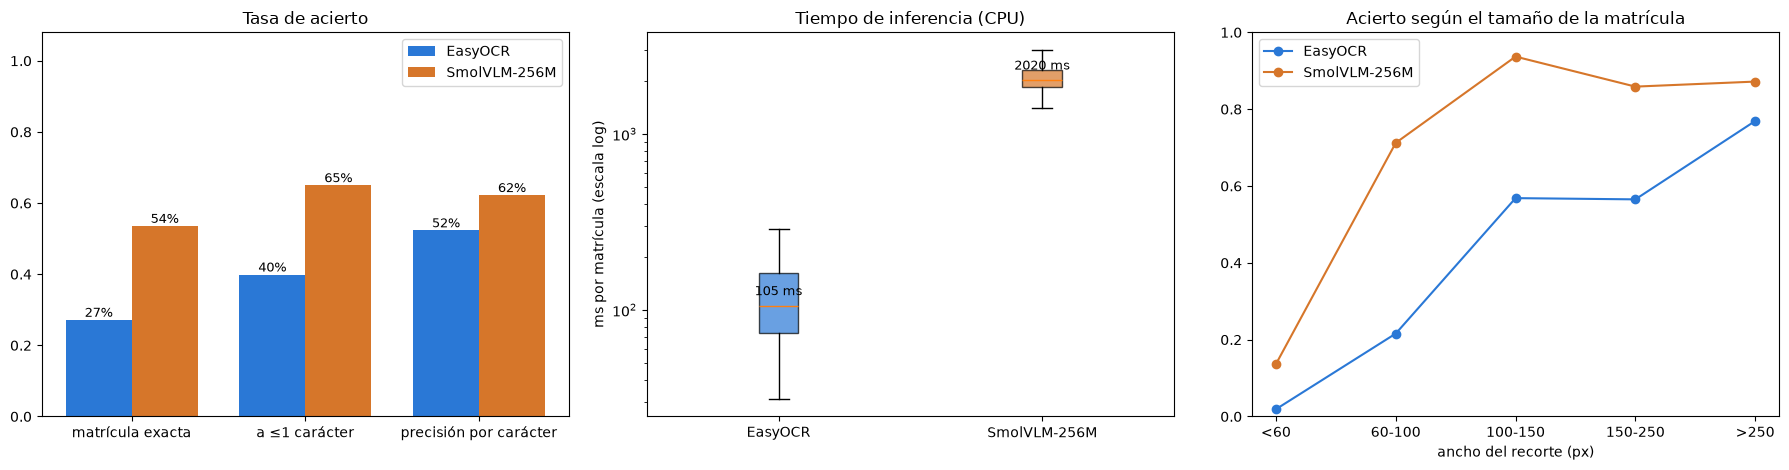

In [7]:
COL = {'EasyOCR': '#2a78d6', 'SmolVLM-256M': '#d6762a'}
fig, axs = plt.subplots(1, 3, figsize=(18, 4.8))

x = np.arange(3); w = 0.38
for k, m in enumerate(MODS):
    v = [tabla.loc[m, 'acierto_matricula'], tabla.loc[m, 'a_1_caracter'], tabla.loc[m, 'precision_caracter']]
    b = axs[0].bar(x + (k - 0.5) * w, v, w, label=m, color=COL[m])
    axs[0].bar_label(b, [f'{p:.0%}' for p in v], fontsize=9)
axs[0].set_xticks(x, ['matrícula exacta', 'a ≤1 carácter', 'precisión por carácter'])
axs[0].set_ylim(0, 1.08); axs[0].set_title('Tasa de acierto'); axs[0].legend()

bp = axs[1].boxplot([comp[comp.modelo == m].tiempo_s * 1000 for m in MODS], showfliers=False, patch_artist=True)
for p, m in zip(bp['boxes'], MODS):
    p.set_facecolor(COL[m]); p.set_alpha(0.7)
axs[1].set_xticks([1, 2], MODS)
axs[1].set_yscale('log'); axs[1].set_ylabel('ms por matrícula (escala log)'); axs[1].set_title('Tiempo de inferencia (CPU)')
for k, m in enumerate(MODS, 1):
    axs[1].text(k, tabla.loc[m, 'tiempo_mediana_ms'] * 1.15, f"{tabla.loc[m, 'tiempo_mediana_ms']:.0f} ms", ha='center', fontsize=9)

for m in MODS:
    axs[2].plot(etq, por_ancho[m].values, 'o-', label=m, color=COL[m])
axs[2].set_xlabel('ancho del recorte (px)'); axs[2].set_ylim(0, 1); axs[2].set_title('Acierto según el tamaño de la matrícula'); axs[2].legend()
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, 'comparativa_ocr.png'), dpi=110, bbox_inches='tight'); plt.show()

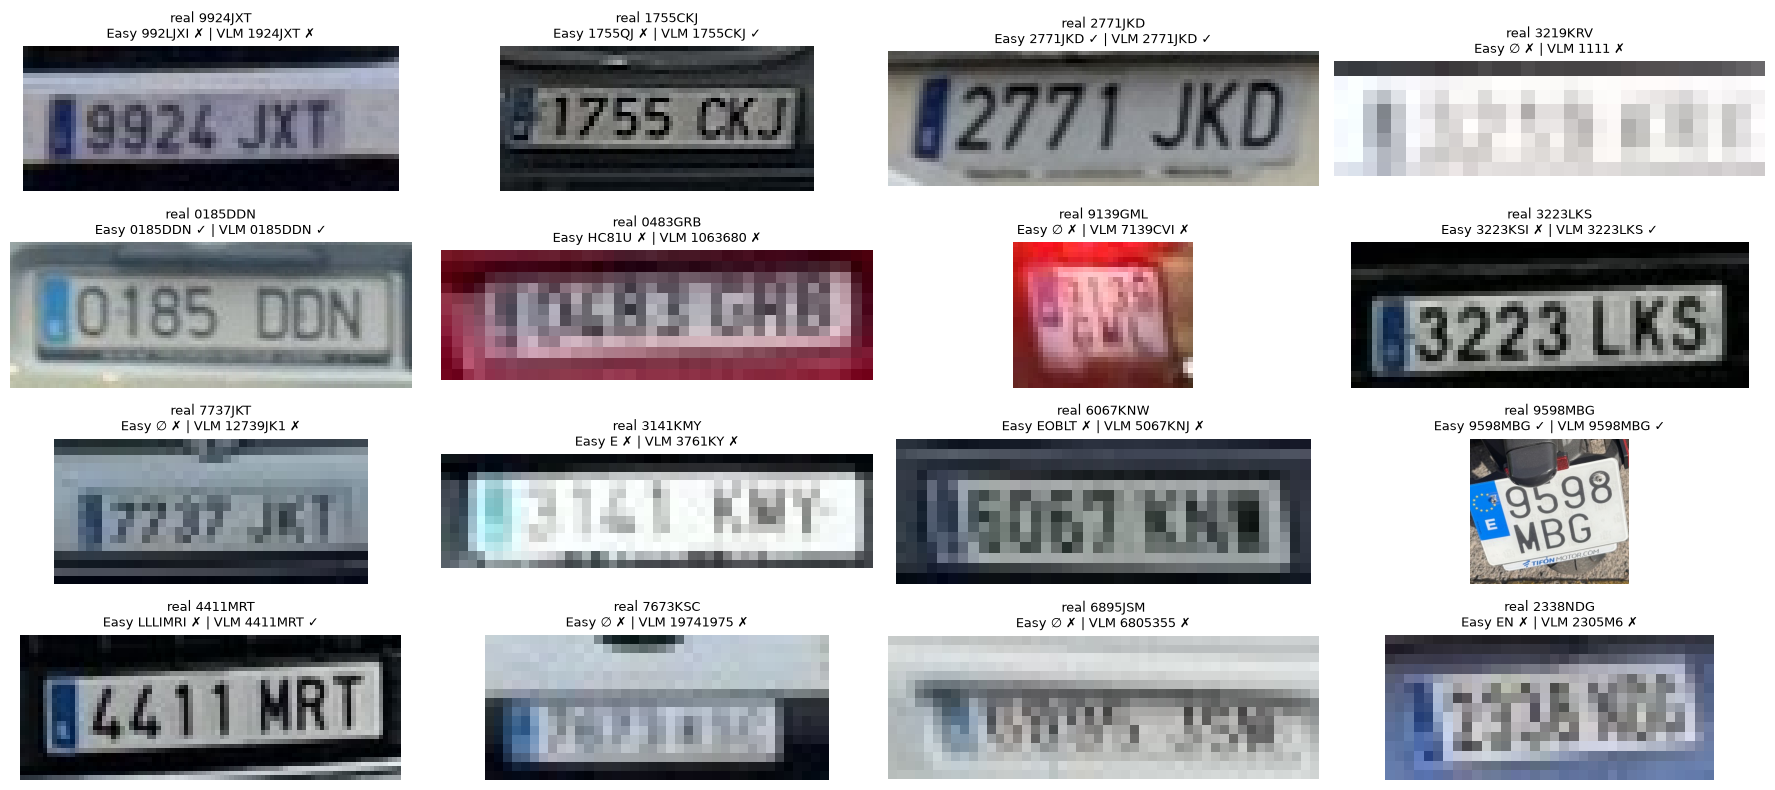

Salidas brutas de SmolVLM en algunos fallos:


,texto_real,salida_bruta,prediccion
632,2062MTM,2007,2007
633,8838LKV,TBD,TBD
636,6668DNJ,K55DU,K55DU
637,1899LBK,2222222222,2222222222
640,6118NFB,6118 MF8,6118MF8
641,2980GZV,29020,29020
645,3144JRS,3144 JR5,3144JR5
646,1044MPN,111111111111111,111111111111111
647,6927JFK,6522 JX,6522JX
648,0643DZG,0643 02G.,064302G


In [8]:
# Ejemplos: aciertos y errores de cada modelo
salida = comp.pivot_table(index='id', columns='modelo', values='prediccion', aggfunc='first')[MODS]
rec = ev.set_index('id')
random.seed(4)
ids = random.sample(list(salida.index), 16)
fig, axs = plt.subplots(4, 4, figsize=(18, 8))
for ax, i in zip(axs.ravel(), ids):
    ax.imshow(rec.recorte[i][:, :, ::-1]); ax.axis('off')
    real = rec.texto_real[i]
    marca = lambda p: f'{p or "∅"} {"✓" if p == real else "✗"}'
    ax.set_title(f'real {real}\nEasy {marca(salida.EasyOCR[i])} | VLM {marca(salida["SmolVLM-256M"][i])}', fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, 'ejemplos_ocr.png'), dpi=100, bbox_inches='tight'); plt.show()

print('Salidas brutas de SmolVLM en algunos fallos:')
display(comp[(comp.modelo == 'SmolVLM-256M') & ~comp.acierto][['texto_real', 'salida_bruta', 'prediccion']].head(12))

## 4. Integración en el prototipo de la P4

Se parte de las detecciones y el seguimiento de la P4 (`../P4/resultados/detecciones.csv`), así que se mantienen los mismos *tracks*, conteos y cajas,
y se vuelve a recorrer el vídeo `C0142.MP4`.

**Problema:** las matrículas del vídeo son mucho peores que las del dataset. Son pequeñas (mediana de 42×12 px) y, cuando el coche pasa cerca de la cámara
y la matrícula se ve grande, sale muy movida. En las pruebas, EasyOCR no sacaba casi nada ni siquiera en las matrículas que se leen a simple vista.
Leer todos los fotogramas también sería poco eficiente, porque la mayoría de los recortes son ilegibles.

**Estrategia: leer pocos recortes, pero buenos, y votar por vehículo.**

1. En una primera pasada se recortan todas las matrículas detectadas (con el mismo margen y preprocesado de la comparativa) y se mide su **nitidez**
   (varianza del laplaciano sobre el recorte reescalado a 64 px de alto).
2. Para cada vehículo (`identificador_tracking`) se escogen los `K = 5` recortes **más nítidos** de al menos 30 px de ancho,
   y se leen con **SmolVLM**, el mejor de la comparativa. Así son unas 250 lecturas en lugar de ~1 900.
   Los mismos recortes se leen también con EasyOCR, para comparar los dos en el vídeo (`resultados/lecturas_video.csv`).
3. La lectura de SmolVLM, si tiene formato válido, se guarda en `texto_matricula` de ese fotograma.
4. **Votación por carácter:** entre las lecturas válidas del vehículo se toma la longitud más frecuente y, posición a posición, el carácter más votado.
   Así se combinan lecturas parcialmente erróneas (`1965K8P` + `1965KBP` + …). Solo se acepta el resultado si hay al menos 2 lecturas válidas.
   El texto consolidado va a la columna `texto_matricula_track` y es el que se muestra en el vídeo, encima del vehículo.
5. El vídeo se escribe a 1280×720 para no superar los 100 MB por archivo de GitHub. Las coordenadas del CSV siguen en la resolución original (1920×1080).

In [9]:
VIDEO   = os.path.join(P4, 'C0142.MP4')
CSV_IN  = os.path.join(P4, 'resultados', 'detecciones.csv')
CSV_OUT = os.path.join(OUT_DIR, 'detecciones.csv')
CSV_LEC = os.path.join(OUT_DIR, 'lecturas_video.csv')
MP4_OUT = os.path.join(OUT_DIR, 'resultado_ocr.mp4')
OUT_W, OUT_H = 1280, 720
K_MEJORES, ANCHO_MIN, MIN_LECTURAS = 5, 30, 2

CLASES  = {'persona': 0, 'bicicleta': 1, 'coche': 2, 'moto': 3, 'autobus': 5, 'camion': 7}
COLORES = {0: (0, 200, 255), 1: (255, 160, 0), 2: (0, 255, 0), 3: (255, 0, 255), 5: (255, 255, 0), 7: (0, 128, 255)}
MIN_FRAMES = 5

det = pd.read_csv(CSV_IN, keep_default_na=False, dtype={'texto_matricula': str})
porframe = det.groupby('fotograma').groups
es_valida = lambda p: bool(FORMATO_ACTUAL.fullmatch(p) or FORMATO_ANTIGUO.fullmatch(p))

def margen_caja(img, x1, y1, x2, y2):
    w, h = x2 - x1, y2 - y1
    H, W = img.shape[:2]
    return img[max(0, int(y1 - MARGEN_Y*h)):min(H, int(y2 + MARGEN_Y*h)), max(0, int(x1 - MARGEN_X*w)):min(W, int(x2 + MARGEN_X*w))]

def nitidez(c):
    return cv2.Laplacian(cv2.cvtColor(preprocesa(c), cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()

# --- Pasada 1: recortar todas las matrículas detectadas y medir su nitidez ---
cap = cv2.VideoCapture(VIDEO); fps = cap.get(cv2.CAP_PROP_FPS)
recortes, cand = {}, []
nf = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    for i in porframe.get(nf, []):
        r = det.loc[i]
        if r.matricula_en_su_caso != 'si' or int(r.identificador_tracking) < 0:
            continue
        c = margen_caja(frame, *(int(float(r[k])) for k in ('mx1', 'my1', 'mx2', 'my2')))
        if c.shape[1] < ANCHO_MIN or c.shape[0] < 6:
            continue
        recortes[i] = c.copy()
        cand.append({'fila': i, 'fotograma': nf, 'identificador_tracking': int(r.identificador_tracking),
                     'ancho_px': c.shape[1], 'nitidez': nitidez(c)})
    nf += 1
cap.release()
cand = pd.DataFrame(cand)
sel = cand.sort_values('nitidez', ascending=False).groupby('identificador_tracking').head(K_MEJORES)
print(f'{nf} fotogramas; matrículas de al menos {ANCHO_MIN} px: {len(cand)} de {(det.matricula_en_su_caso == "si").sum()} '
      f'({cand.identificador_tracking.nunique()} vehículos); seleccionadas para leer: {len(sel)}')

# --- Lectura de los recortes seleccionados con los dos modelos ---
lect = []
t0 = time.time()
for s in sel.itertuples():
    c = preprocesa(recortes[s.fila])
    fila = s._asdict()
    for nombre, f in MODELOS.items():
        t1 = time.perf_counter(); bruto, _ = f(c)
        fila[nombre] = normaliza(bruto); fila[f't_{nombre}'] = time.perf_counter() - t1
    lect.append(fila)
lect = pd.DataFrame(lect).drop(columns='Index')
lect.to_csv(CSV_LEC, index=False)
print(f'{len(lect)} recortes leídos en {time.time() - t0:.0f} s')
for nombre in MODELOS:
    print(f'  {nombre:13s} lecturas con formato válido: {lect[nombre].map(es_valida).mean():.1%}  '
          f'(tiempo medio {1000 * lect[f"t_{nombre}"].mean():.0f} ms)')

2832 fotogramas; matrículas de al menos 30 px: 1602 de 1926 (28 vehículos); seleccionadas para leer: 140


/home/tomas/miniconda3/envs/VC_P4/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


140 recortes leídos en 310 s
  EasyOCR       lecturas con formato válido: 2.9%  (tiempo medio 120 ms)
  SmolVLM-256M  lecturas con formato válido: 20.0%  (tiempo medio 2095 ms)


In [10]:
# --- Votación por carácter de las lecturas de SmolVLM de cada vehículo ---
def vota(lecturas):
    lecturas = [l for l in lecturas if es_valida(l)]
    if len(lecturas) < MIN_LECTURAS:
        return '', len(lecturas)
    n = Counter(map(len, lecturas)).most_common(1)[0][0]
    misma = [l for l in lecturas if len(l) == n]
    return ''.join(Counter(l[k] for l in misma).most_common(1)[0][0] for k in range(n)), len(lecturas)

VLM = 'SmolVLM-256M'
det['texto_matricula'] = ''
for fila, txt in zip(lect.fila, lect[VLM]):
    if es_valida(txt):
        det.at[fila, 'texto_matricula'] = txt

consolidado, apoyo = {}, {}
for tid, g in lect.groupby('identificador_tracking'):
    txt, n = vota(list(g[VLM]))
    if txt:
        consolidado[tid], apoyo[tid] = txt, n
det['texto_matricula_track'] = det.identificador_tracking.map(consolidado).fillna('')
det.to_csv(CSV_OUT, index=False)
print(f'Vehículos con matrícula detectada: {det[det.matricula_en_su_caso == "si"].identificador_tracking.nunique()}, '
      f'con recortes legibles (≥{ANCHO_MIN} px): {lect.identificador_tracking.nunique()}, '
      f'con matrícula consolidada: {len(consolidado)} -> {CSV_OUT}')

Vehículos con matrícula detectada: 60, con recortes legibles (≥30 px): 28, con matrícula consolidada: 8 -> resultados/detecciones.csv


In [11]:
# --- Pasada 2: vídeo con detecciones, seguimiento, conteo y matrícula leída ---
cap = cv2.VideoCapture(VIDEO)
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
out = cv2.VideoWriter(MP4_OUT, cv2.VideoWriter_fourcc(*'mp4v'), fps, (OUT_W, OUT_H))
tracks = defaultdict(lambda: {'cls': None, 'n': 0})
NOMBRE = {v: k for k, v in CLASES.items()}
FRAMES_EJEMPLO = (700, 1400, 2100)
# Fotograma en que aparece por primera vez cada vehículo con matrícula leída (para el contador en pantalla)
primera = det[det.texto_matricula_track != ''].groupby('identificador_tracking').fotograma.min().values

def texto_con_fondo(img, txt, x, y, escala, color_txt, color_fondo, grosor=2):
    (tw, th), base = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, escala, grosor)
    x, y = max(0, min(x, img.shape[1] - tw - 4)), max(th + 4, y)
    cv2.rectangle(img, (x, y - th - 4), (x + tw + 4, y + base), color_fondo, -1)
    cv2.putText(img, txt, (x + 2, y - 2), cv2.FONT_HERSHEY_SIMPLEX, escala, color_txt, grosor)

nf = 0
while True:
    ok, vis = cap.read()
    if not ok:
        break
    for i in porframe.get(nf, []):
        r = det.loc[i]; cls = CLASES[r.tipo_objeto]; col = COLORES[cls]; tid = int(r.identificador_tracking)
        x1, y1, x2, y2 = (int(r[k]) for k in ('x1', 'y1', 'x2', 'y2'))
        if tid >= 0:
            tracks[tid]['cls'] = cls; tracks[tid]['n'] += 1
        cv2.rectangle(vis, (x1, y1), (x2, y2), col, 2)
        cv2.putText(vis, f'{r.tipo_objeto} {tid if tid >= 0 else "?"} {float(r.confianza):.2f}', (x1, max(15, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2)
        if r.matricula_en_su_caso == 'si':
            mx1, my1, mx2, my2 = (int(float(r[k])) for k in ('mx1', 'my1', 'mx2', 'my2'))
            cv2.rectangle(vis, (mx1, my1), (mx2, my2), (0, 0, 255), 2)
            if r.texto_matricula:   # lectura de este fotograma, junto a la matrícula
                cv2.putText(vis, r.texto_matricula, (mx1, my2 + 16), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
        if r.texto_matricula_track:  # texto consolidado del vehículo, bien visible
            texto_con_fondo(vis, r.texto_matricula_track, x1, y1 - 26, 0.9, (0, 0, 0), (255, 255, 255))

    cuenta = Counter(NOMBRE[t['cls']] for t in tracks.values() if t['n'] >= MIN_FRAMES)
    leidas = int((primera <= nf).sum())
    cv2.rectangle(vis, (0, 0), (W, 32), (0, 0, 0), -1)
    cv2.putText(vis, f'Frame {nf}   ' + '  '.join(f'{k}: {v}' for k, v in sorted(cuenta.items())) + f'   matriculas leidas: {leidas}',
                (10, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    out.write(cv2.resize(vis, (OUT_W, OUT_H), interpolation=cv2.INTER_AREA))
    if nf in FRAMES_EJEMPLO:
        cv2.imwrite(os.path.join(IMG_DIR, f'resultado_ocr_f{nf}.jpg'), vis)
    nf += 1
cap.release(); out.release()
print(f'Vídeo guardado: {MP4_OUT} ({os.path.getsize(MP4_OUT) / 2**20:.0f} MB)')

Vídeo guardado: resultados/resultado_ocr.mp4 (71 MB)


,tipo,matricula,fotogramas_con_matricula,lecturas_validas,lecturas_coincidentes,consenso
identificador_tracking,,,,,,
647,coche,1965KBP,88,4,4,1.00
540,coche,1770JYG,86,4,3,0.75
96,coche,3713LKC,91,3,3,1.00
338,coche,0053JFM,68,3,3,1.00
469,coche,8536LKJ,93,3,3,1.00
611,coche,0092JUM,52,3,0,0.00
416,coche,3902FWD,57,2,1,0.50
277,coche,2914FGM,63,2,1,0.50


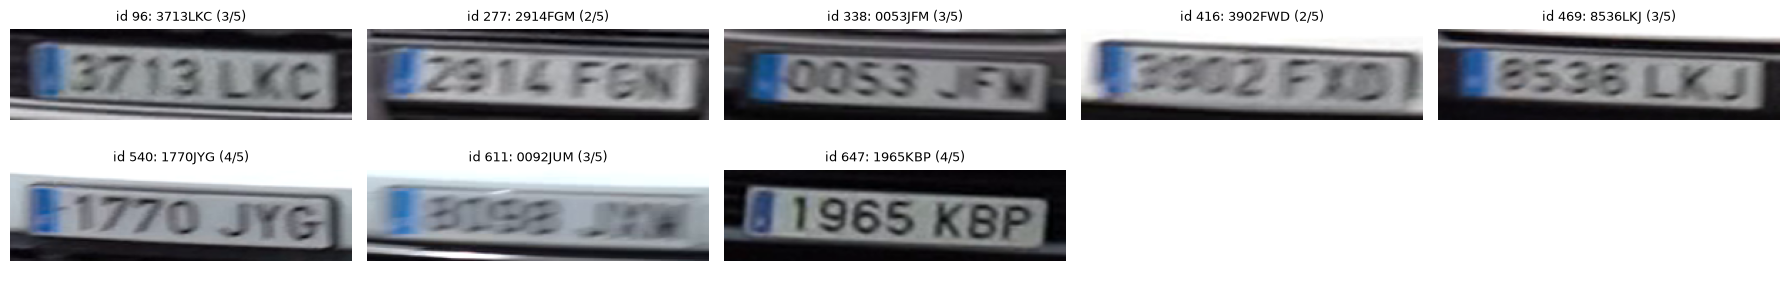

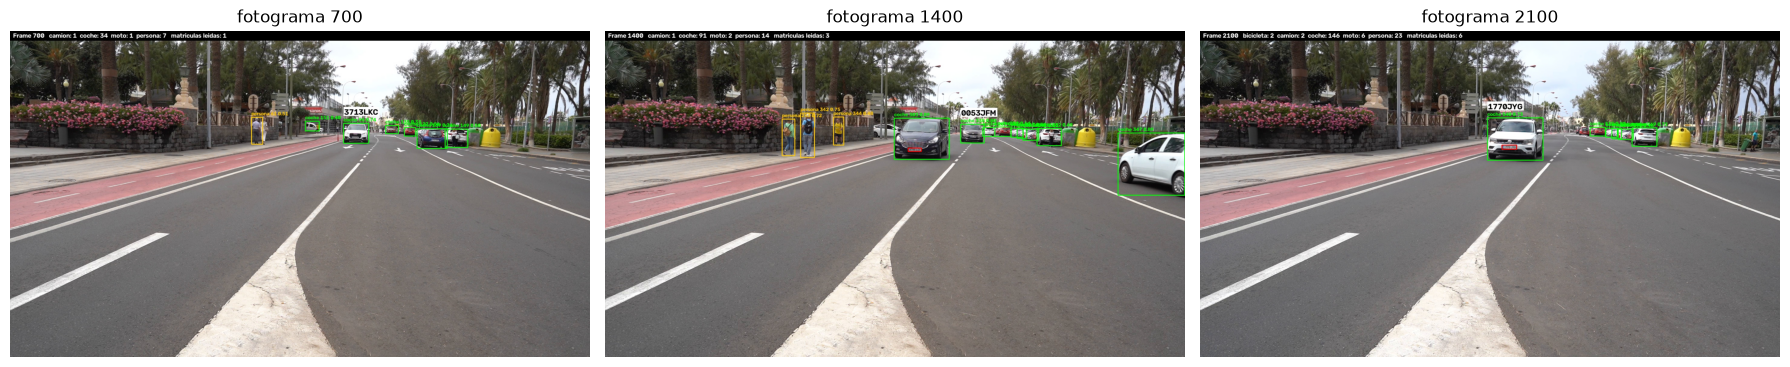

In [12]:
# Matrículas leídas por vehículo (texto consolidado) y número de lecturas que lo respaldan
res = (det[det.texto_matricula_track != '']
       .groupby('identificador_tracking')
       .agg(tipo=('tipo_objeto', 'last'), matricula=('texto_matricula_track', 'first'),
            fotogramas_con_matricula=('matricula_en_su_caso', lambda s: (s == 'si').sum()),
            lecturas_validas=('texto_matricula', lambda s: (s != '').sum())))
coincide = det[det.texto_matricula == det.texto_matricula_track].groupby('identificador_tracking').size()
res['lecturas_coincidentes'] = coincide.reindex(res.index).fillna(0).astype(int)
res['consenso'] = res.lecturas_coincidentes / res.lecturas_validas
display(res.sort_values('lecturas_validas', ascending=False))

# Verificación visual: recorte más nítido de cada vehículo con la matrícula consolidada
mejor = lect.sort_values('nitidez', ascending=False).groupby('identificador_tracking').head(1)
mejor = mejor[mejor.identificador_tracking.isin(consolidado)].sort_values('identificador_tracking')
n = len(mejor); cols = 5; filas_m = max(1, int(np.ceil(n / cols)))
fig, axs = plt.subplots(filas_m, cols, figsize=(18, 1.6 * filas_m), squeeze=False)
for ax in axs.ravel():
    ax.axis('off')
for ax, s in zip(axs.ravel(), mejor.itertuples()):
    ax.imshow(cv2.resize(preprocesa(recortes[s.fila]), (240, 64))[:, :, ::-1])
    ax.set_title(f'id {s.identificador_tracking}: {consolidado[s.identificador_tracking]} ({apoyo[s.identificador_tracking]}/{K_MEJORES})', fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(IMG_DIR, 'matriculas_video.png'), dpi=100, bbox_inches='tight'); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for ax, f in zip(axs, (700, 1400, 2100)):
    p = os.path.join(IMG_DIR, f'resultado_ocr_f{f}.jpg')
    if os.path.exists(p):
        ax.imshow(cv2.imread(p)[:, :, ::-1])
    ax.set_title(f'fotograma {f}'); ax.axis('off')
plt.tight_layout(); plt.show()